# A simple Swedish catchment hydrograph

This notebook runs the project's small daily snow-and-soil model and plots its response. The included forcing in `data/educational_forcing.csv` is **synthetic**, and the 12 km² catchment and model parameters are illustrative—not measurements or a calibration for a real Swedish basin.

The model tracks snow storage, soil water, and groundwater. Rain and snowmelt feed the soil bucket; the model then calculates quickflow, evapotranspiration, drainage, and baseflow.

In [1]:
from pathlib import Path
import sys

import matplotlib.dates as mdates
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from motala_hydro import ModelParameters, read_forcing_csv, simulate

## Create illustrative daily weather

The CSV was generated deterministically by `scripts/generate_synthetic_forcing.py`. A smooth seasonal warming and a handful of rain events make snow storage, melt, and runoff response easier to see. These values are for teaching and should not be used as observed weather.

In [2]:
forcing_path = PROJECT_ROOT / "data" / "educational_forcing.csv"
with forcing_path.open(newline="", encoding="utf-8") as forcing_file:
    forcings = read_forcing_csv(forcing_file)

area_km2 = 12.0
parameters = ModelParameters()
results = simulate(forcings, area_km2=area_km2, parameters=parameters)

peak = max(results, key=lambda row: row.discharge_m3_s)
print(f"Catchment area: {area_km2:.1f} km²")
print(f"Synthetic period: {results[0].day} to {results[-1].day} ({len(results)} days)")
print(f"Total precipitation: {sum(row.precipitation_mm for row in results):.1f} mm")
print(f"Peak modeled flow: {peak.discharge_m3_s:.3f} m³/s on {peak.day}")
print(f"Maximum absolute daily water-balance error: {max(abs(row.water_balance_error_mm) for row in results):.2e} mm")

Catchment area: 12.0 km²
Synthetic period: 2026-03-01 to 2026-05-29 (90 days)
Total precipitation: 155.0 mm
Peak modeled flow: 0.203 m³/s on 2026-04-30
Maximum absolute daily water-balance error: 1.60e-14 mm


## Read the hydrograph

The top panel compares precipitation with temperature (snowfall is possible below the model's rain/snow transition). The middle panel shows snow water remaining in storage. The bottom panel is the hydrograph: quickflow responds to rain and melt, while groundwater baseflow changes more gradually. Flow components are shown in m³/s for the stated catchment area.

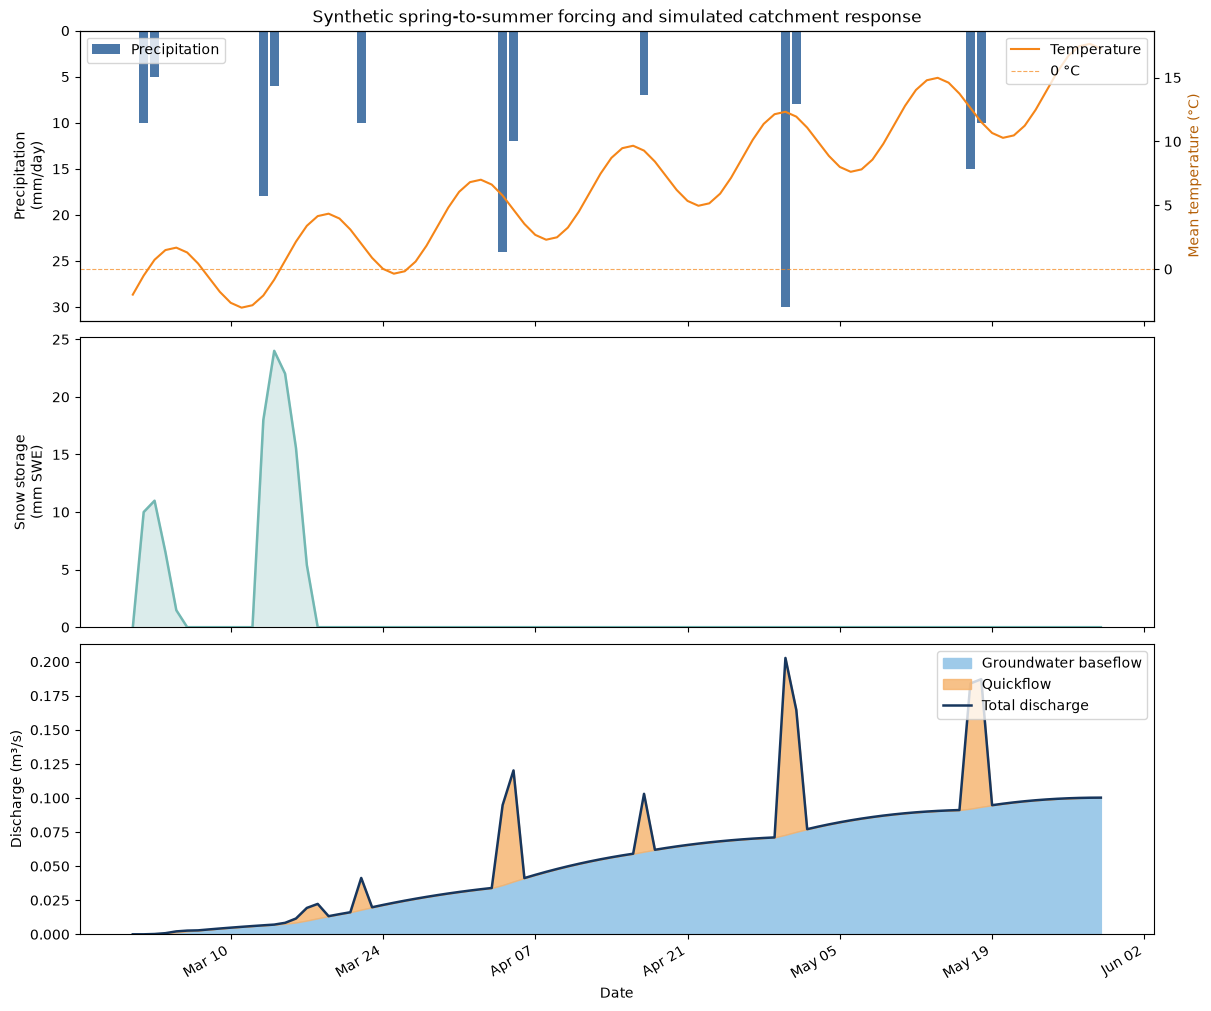

In [3]:
days = [row.day for row in results]
precipitation = [row.precipitation_mm for row in results]
temperature = [forcing.mean_temp_c for forcing in forcings]
snow_storage = [row.snow_storage_mm for row in results]
quickflow = [row.quickflow_mm * area_km2 * 1000 / 86400 for row in results]
baseflow = [row.baseflow_mm * area_km2 * 1000 / 86400 for row in results]
total_flow = [row.discharge_m3_s for row in results]

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True, constrained_layout=True)

axes[0].bar(days, precipitation, width=0.8, color="#4c78a8")
axes[0].invert_yaxis()
axes[0].set_ylabel("Precipitation\n(mm/day)")
axes[0].set_title("Synthetic spring-to-summer forcing and simulated catchment response")
temperature_axis = axes[0].twinx()
temperature_axis.plot(days, temperature, color="#f58518", linewidth=1.5)
temperature_axis.axhline(0, color="#f58518", linestyle="--", linewidth=0.8, alpha=0.7)
temperature_axis.set_ylabel("Mean temperature (°C)", color="#b45f06")
axes[0].legend(["Precipitation"], loc="upper left")
temperature_axis.legend(["Temperature", "0 °C"], loc="upper right")

axes[1].plot(days, snow_storage, color="#72b7b2", linewidth=1.8)
axes[1].fill_between(days, snow_storage, color="#72b7b2", alpha=0.25)
axes[1].set_ylabel("Snow storage\n(mm SWE)")
axes[1].set_ylim(bottom=0)

axes[2].fill_between(days, 0, baseflow, color="#9ecae9", label="Groundwater baseflow")
axes[2].fill_between(days, baseflow, [q + b for q, b in zip(quickflow, baseflow)],
                     color="#f6b26b", alpha=0.8, label="Quickflow")
axes[2].plot(days, total_flow, color="#17365d", linewidth=1.8, label="Total discharge")
axes[2].set_ylabel("Discharge (m³/s)")
axes[2].set_xlabel("Date")
axes[2].set_ylim(bottom=0)
axes[2].legend(loc="upper right")

axes[2].xaxis.set_major_locator(mdates.WeekdayLocator(interval=2))
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
fig.autofmt_xdate()
plt.show()

### Discussion prompts

- How does warming change the balance between snowfall and rainfall?
- Which storms produce the largest quickflow peaks, and how wet was the soil beforehand?
- What happens to the hydrograph if you change `soil_capacity_mm`, `degree_day_factor_mm_c_day`, or `baseflow_fraction_day` above?

The hydrograph is only a conceptual demonstration. Real catchments need observed precipitation, temperature, and PET, plus parameter calibration and evaluation against measured flow.